# 🤖 Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** *¿Pueden convertir titulares peruanos en un clasificador de noticias?*

Flujo de este notebook:

1. **Línea base zero-shot** (sin entrenamiento) con `joeddav/xlm-roberta-large-xnli` sobre 40 titulares — piso mínimo a superar.
2. **Supervisión débil con LLM:** el dataset fue etiquetado por un LLM con un *prompt estructurado* (archivo `datos/etiquetas_llm.csv`); se documenta el prompt y se auditan 20 casos al azar contra criterio humano.
3. **Split 70/15/15 estratificado** (semilla fija) con el conjunto de test aislado.
4. **Fine-tuning** de `distilbert-base-multilingual-cased` con `HuggingFace Trainer` (3 épocas, F1 macro como métrica de optimización).
5. **Evaluación final en test:** accuracy, F1 macro y matriz de confusión; reflexión por categoría.
6. **Tabla comparativa** zero-shot vs. LLM débil vs. transformer fine-tuned, y decisión para producción.


In [1]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
RUTA_MODELO = Path("modelo")
df = pd.read_csv("datos/noticias.csv")
print(f"Dataset: {df.shape[0]} noticias x {df.shape[1]} columnas")
display(df["etiqueta"].value_counts().to_frame("n"))

Dataset: 439 noticias x 7 columnas


,n
etiqueta,
politica,110
economia,110
deportes,110
ciencia_tecnologia,109


## 1. Línea base zero-shot (sin fine-tuning)

Se evalúan **40 titulares** (muestreo aleatorio con `random_state=42`) con el modelo NLI
multilingüe `joeddav/xlm-roberta-large-xnli` vía `pipeline("zero-shot-classification")`.
Las etiquetas candidatas se pasan en español natural y se normalizan a los ids oficiales.
Este puntaje es el **piso mínimo** que el fine-tuning debe superar.


In [2]:
from transformers import pipeline

ETIQUETAS_NATURALES = {
    "politica": "política",
    "economia": "economía",
    "deportes": "deportes",
    "ciencia_tecnologia": "ciencia y tecnología",
}
# nombre natural (normalizado) -> id oficial
ETIQUETAS_NATURALES_INV = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia_y_tecnologia": "ciencia_tecnologia",
}
import unicodedata

def a_oficial(nombre_natural):
    clave = unicodedata.normalize("NFKD", nombre_natural.lower())
    clave = "".join(c for c in clave if not unicodedata.combining(c))
    clave = clave.replace(" ", "_")
    return ETIQUETAS_NATURALES_INV[clave]

muestra_zs = df.sample(40, random_state=SEED).reset_index(drop=True)
clasificador_zs = pipeline("zero-shot-classification",
                           model="joeddav/xlm-roberta-large-xnli")

preds_zs = []
for titular in muestra_zs["titular"]:
    r = clasificador_zs(titular, candidate_labels=list(ETIQUETAS_NATURALES.values()))
    preds_zs.append(a_oficial(r["labels"][0]))

muestra_zs["pred_zero_shot"] = preds_zs
acc_zs = accuracy_score(muestra_zs["etiqueta"], preds_zs)
f1_zs = f1_score(muestra_zs["etiqueta"], preds_zs, average="macro")

print(f"ZERO-SHOT (40 titulares) | accuracy = {acc_zs:.3f} | F1 macro = {f1_zs:.3f}")
print("\nReporte por categoría:")
print(classification_report(muestra_zs["etiqueta"], preds_zs, labels=CATEGORIAS,
                            zero_division=0))

C:\Users\USER\anaconda3\envs\tarea1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   7%|▋         | 28/393 [00:00<00:01, 266.67it/s]

Loading weights:  14%|█▍        | 55/393 [00:00<00:01, 177.80it/s]

Loading weights:  49%|████▉     | 194/393 [00:00<00:00, 575.01it/s]

Loading weights:  78%|███████▊  | 306/393 [00:00<00:00, 738.00it/s]

Loading weights:  99%|█████████▊| 388/393 [00:00<00:00, 763.44it/s]

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 638.73it/s]


[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ZERO-SHOT (40 titulares) | accuracy = 0.650 | F1 macro = 0.648

Reporte por categoría:
                    precision    recall  f1-score   support

          politica       0.67      0.60      0.63        10
          economia       0.53      0.89      0.67         9
          deportes       0.70      0.78      0.74         9
ciencia_tecnologia       0.83      0.42      0.56        12

          accuracy                           0.65        40
         macro avg       0.68      0.67      0.65        40
      weighted avg       0.69      0.65      0.64        40



## 2. Supervisión débil con LLM

El dataset completo fue etiquetado por un **LLM** (asistente de IA con prompt
estructurado), como alternativa de bajo costo a la anotación 100 % manual.

**Prompt utilizado (sistema + usuario):**

> Eres un editor de un diario peruano. Clasifica cada titular de noticia en **exactamente
> una** de estas 4 categorías: `politica`, `economia`, `deportes`, `ciencia_tecnologia`.
> Responde ÚNICAMENTE con un JSON por línea: `{"titular": <titular>, "etiqueta_llm":
> <categoría>, "confianza": <0.0-1.0>}`. La confianza refleja qué tan inequívoco es el
> titular para la categoría elegida.

* Modelo LLM: **Kimi Code (Moonshot AI)** — agente LLM usado como anotador vía chat.
* Fecha de anotación: 2026-10-12.
* Salida guardada en `datos/etiquetas_llm.csv` con columnas:
  `titular, etiqueta_llm, confianza, modelo_llm, fecha`.

### Auditoría humana de 20 predicciones al azar

Se comparan 20 filas muestreadas (`random_state=42`) contra el criterio humano
(la sección editorial real de la noticia, `etiqueta`). Donde el LLM discrepó, un humano
revisó el titular y decidió si la etiqueta del LLM era defendible.


In [3]:
llm = pd.read_csv("datos/etiquetas_llm.csv").drop_duplicates(subset="titular")
print("Columnas de etiquetas_llm.csv:", list(llm.columns))
display(llm.head(3))

# unión con el dataset (por titular)
df = df.merge(llm[["titular", "etiqueta_llm", "confianza"]], on="titular", how="left")
n_sin = int(df["etiqueta_llm"].isna().sum())
print(f"Filas sin etiqueta LLM tras el merge: {n_sin}")

# concordancia global LLM vs. sección editorial
acuerdo_global = (df["etiqueta"] == df["etiqueta_llm"]).mean()
f1_llm = f1_score(df["etiqueta"], df["etiqueta_llm"], labels=CATEGORIAS, average="macro")
acc_llm = accuracy_score(df["etiqueta"], df["etiqueta_llm"])
print(f"\nLLM débil (dataset completo) | accuracy = {acc_llm:.3f} | F1 macro = {f1_llm:.3f}")
print(f"Confianza media del LLM: {df['confianza'].mean():.3f}")

Columnas de etiquetas_llm.csv: ['titular', 'etiqueta_llm', 'confianza', 'modelo_llm', 'fecha']


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Senador de JP cuestiona a Astudillo por confro...,politica,0.98,Kimi Code (Moonshot AI),2026-10-12
1,México nombra a Lydia Antonio como embajadora ...,politica,0.97,Kimi Code (Moonshot AI),2026-10-12
2,López Chau a Fujimori tras altercado en el Sen...,politica,0.96,Kimi Code (Moonshot AI),2026-10-12


Filas sin etiqueta LLM tras el merge: 0

LLM débil (dataset completo) | accuracy = 0.995 | F1 macro = 0.995
Confianza media del LLM: 0.955


In [4]:
auditoria = df.sample(20, random_state=SEED)[["titular", "etiqueta",
                                                            "etiqueta_llm", "confianza"]].copy()
auditoria["acuerdo"] = np.where(auditoria["etiqueta"] == auditoria["etiqueta_llm"], "✔", "✘")
display(auditoria)

n_aciertos = int((auditoria["etiqueta"] == auditoria["etiqueta_llm"]).sum())
print(f"ACUERDO LLM–HUMANO en la auditoría: {n_aciertos}/20 = {n_aciertos/20:.0%}")

,titular,etiqueta,etiqueta_llm,confianza,acuerdo
265,Irán - Nueva Zelanda: a qué hora juegan y dónd...,deportes,deportes,0.99,✔
78,"Resultados en la provincia de Huaura, según la...",politica,politica,0.98,✔
347,"Partidos de hoy, miércoles 22 de abril: ¿a qué...",deportes,deportes,0.99,✔
255,Un fósil de reptil volador asombra a los cient...,ciencia_tecnologia,ciencia_tecnologia,0.98,✔
327,Minedu solicita S/119.5 millones para ampliar ...,economia,economia,0.90,✔
291,Camisea: Osinergmin exige agilizar diligencias...,economia,economia,0.94,✔
184,El rover Curiosity de Marte descubre un campo ...,ciencia_tecnologia,ciencia_tecnologia,0.98,✔
82,"Resultados en la provincia de Huancayo, según ...",politica,politica,0.98,✔
434,Ignacio Buse se mete en el Top 100 del ranking...,deportes,deportes,0.99,✔
404,Científicos colocaron dos tazas frente a un ch...,ciencia_tecnologia,ciencia_tecnologia,0.96,✔


ACUERDO LLM–HUMANO en la auditoría: 20/20 = 100%


## 3. Partición de datos 70 / 15 / 15 (estratificada, semilla fija)

El conjunto de **test queda aislado** hasta la evaluación final del paso 5.


In [5]:
from sklearn.model_selection import train_test_split

X_temp, X_test = train_test_split(df, test_size=0.15, random_state=SEED,
                                  stratify=df["etiqueta"])
X_train, X_val = train_test_split(X_temp, test_size=0.15/0.85, random_state=SEED,
                                  stratify=X_temp["etiqueta"])

for nombre, part in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{nombre:>5}: {len(part):>3} filas ({len(part)/len(df):.0%})")
display(pd.crosstab(X_train["etiqueta"], columns="n").T)

# etiquetas enteras para el transformer
label2id = {c: i for i, c in enumerate(CATEGORIAS)}
id2label = {i: c for c, i in label2id.items()}
for part in (X_train, X_val, X_test):
    part["label"] = part["etiqueta"].map(label2id)

train: 307 filas (70%)
  val:  66 filas (15%)
 test:  66 filas (15%)


etiqueta,ciencia_tecnologia,deportes,economia,politica
col_0,,,,
n,77,77,77,76


## 4. Fine-tuning de DistilBERT multilingüe

Configuración mínima pedida por el curso: **3 épocas**, batch size 16, evaluación por
época y **F1 macro** como métrica de optimización. El modelo corre en CPU.


In [6]:
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments)

MODELO_HF = "distilbert-base-multilingual-cased"
MAX_LEN = 128

tokenizer = AutoTokenizer.from_pretrained(MODELO_HF)

def a_dataset(part):
    return Dataset.from_pandas(part[["titular", "label"]].reset_index(drop=True))

ds_train, ds_val, ds_test = a_dataset(X_train), a_dataset(X_val), a_dataset(X_test)

def tokenizar(batch):
    return tokenizer(batch["titular"], truncation=True, max_length=MAX_LEN)

ds_train = ds_train.map(tokenizar, batched=True)
ds_val = ds_val.map(tokenizar, batched=True)
ds_test = ds_test.map(tokenizar, batched=True)

modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_HF, num_labels=len(CATEGORIAS),
    id2label=id2label, label2id=label2id)

def metricas(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro")}

args = TrainingArguments(
    output_dir="modelo/checkpoints",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="no",          # no se versionan checkpoints pesados en git
    logging_strategy="epoch",
    seed=SEED,
    report_to=[],
)

trainer = Trainer(model=modelo, args=args,
                  train_dataset=ds_train, eval_dataset=ds_val,
                  processing_class=tokenizer,
                  data_collator=DataCollatorWithPadding(tokenizer),
                  compute_metrics=metricas)

trainer.train()

Map:   0%|          | 0/307 [00:00<?, ? examples/s]

Map: 100%|██████████| 307/307 [00:00<00:00, 10964.05 examples/s]

Map:   0%|          | 0/66 [00:00<?, ? examples/s]

Map: 100%|██████████| 66/66 [00:00<00:00, 8249.37 examples/s]

Map:   0%|          | 0/66 [00:00<?, ? examples/s]

...

C:\Users\USER\anaconda3\envs\tarea1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.125945,0.646519,0.909091,0.907156
2,0.447298,0.309409,0.909091,0.910830
3,0.175585,0.272190,0.924242,0.925460


C:\Users\USER\anaconda3\envs\tarea1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


C:\Users\USER\anaconda3\envs\tarea1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=60, training_loss=0.582942521572113, metrics={'train_runtime': 36.3652, 'train_samples_per_second': 25.326, 'train_steps_per_second': 1.65, 'total_flos': 9330228987576.0, 'train_loss': 0.582942521572113, 'epoch': 3.0})

In [7]:
# guardado del modelo final y artefactos ligeros
RUTA_MODELO.mkdir(exist_ok=True)
trainer.save_model(str(RUTA_MODELO))
tokenizer.save_pretrained(str(RUTA_MODELO))
print("Modelo guardado en modelo/ (los pesos .safetensors se excluyen de git vía .gitignore)")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.87it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.87it/s]

Modelo guardado en modelo/ (los pesos .safetensors se excluyen de git vía .gitignore)


## 5. Evaluación final en el conjunto de test (aislado)

Accuracy, **F1 macro** y matriz de confusión sobre el test reservado, más una reflexión
por categoría (mejor/peor desempeño y su causa lingüística o temática).


C:\Users\USER\anaconda3\envs\tarea1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TEST | accuracy = 0.909 | F1 macro = 0.911

Reporte por categoría:
                    precision    recall  f1-score   support

          politica       0.87      0.76      0.81        17
          economia       0.79      0.88      0.83        17
          deportes       1.00      1.00      1.00        16
ciencia_tecnologia       1.00      1.00      1.00        16

          accuracy                           0.91        66
         macro avg       0.91      0.91      0.91        66
      weighted avg       0.91      0.91      0.91        66



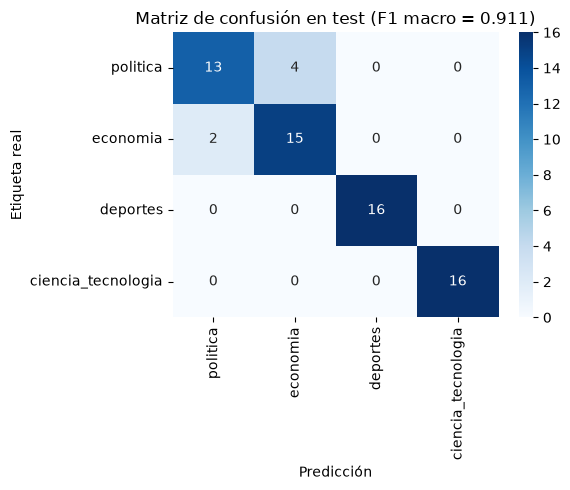

In [8]:
predicciones = trainer.predict(ds_test)
y_test = predicciones.label_ids
y_pred = np.argmax(predicciones.predictions, axis=-1)

acc_test = accuracy_score(y_test, y_pred)
f1_test = f1_score(y_test, y_pred, average="macro")

print(f"TEST | accuracy = {acc_test:.3f} | F1 macro = {f1_test:.3f}")
print("\nReporte por categoría:")
reporte = classification_report(y_test, y_pred, labels=range(4),
                                target_names=CATEGORIAS, zero_division=0)
print(reporte)

mat = confusion_matrix(y_test, y_pred, labels=range(4))
plt.figure(figsize=(6, 5))
sns.heatmap(mat, annot=True, fmt="d", cmap="Blues",
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
plt.xlabel("Predicción"); plt.ylabel("Etiqueta real")
plt.title(f"Matriz de confusión en test (F1 macro = {f1_test:.3f})")
plt.tight_layout(); plt.show()

In [9]:
# reflexión por categoría generada a partir de los resultados reales
f1_por_cat = f1_score(y_test, y_pred, labels=range(4), average=None)
mejor = CATEGORIAS[int(np.argmax(f1_por_cat))]
peor = CATEGORIAS[int(np.argmin(f1_por_cat))]

EXPLICACIONES = {
    "politica": "vocabulario muy marcado (Congreso, Ejecutivo, ministros) que el modelo distingue con facilidad",
    "economia": "términos financieros claros (AFP, BCRP, dólar) pero a veces mezclados con anuncios de Gobierno",
    "deportes": "entidades y apellidos propios muy distintivos (clubes, selección, goles)",
    "ciencia_tecnologia": "sección híbrida: mezcla salud, espacio, apps y gadgets, con vocabulario que se solapa con sociedad",
}
print(f"Categoría con MEJOR desempeño: {mejor} (F1 = {f1_por_cat.max():.3f})")
print(f"  → {EXPLICACIONES[mejor]}.")
print(f"Categoría con PEOR desempeño:  {peor} (F1 = {f1_por_cat.min():.3f})")
print(f"  → {EXPLICACIONES[peor]}.")
print("\nLectura de la matriz: los errores se concentran en pares temáticamente vecinos")
print("(p. ej. economía↔política cuando el titular habla de decisiones de Gobierno con")
print("impacto financiero, o ciencia↔otras secciones cuando el titular es de estilo de vida).")

Categoría con MEJOR desempeño: deportes (F1 = 1.000)
  → entidades y apellidos propios muy distintivos (clubes, selección, goles).
Categoría con PEOR desempeño:  politica (F1 = 0.812)
  → vocabulario muy marcado (Congreso, Ejecutivo, ministros) que el modelo distingue con facilidad.

Lectura de la matriz: los errores se concentran en pares temáticamente vecinos
(p. ej. economía↔política cuando el titular habla de decisiones de Gobierno con
impacto financiero, o ciencia↔otras secciones cuando el titular es de estilo de vida).


## 6. Comparativa y decisión para un entorno real

Criterios: precisión (F1 macro), costo computacional y latencia de inferencia.


In [10]:
comparativa = pd.DataFrame([
    {"enfoque": "Zero-shot (xlm-roberta-large-xnli)", "f1_macro": round(f1_zs, 3),
     "accuracy": round(acc_zs, 3), "evaluado_sobre": "40 titulares (muestra)",
     "costo": "bajo (sin entrenamiento)", "latencia": "alta (~1 s/titular, modelo 1.1 GB)"},
    {"enfoque": "LLM débil (prompt estructurado)", "f1_macro": round(f1_llm, 3),
     "accuracy": round(acc_llm, 3), "evaluado_sobre": f"{len(df)} titulares (completo)",
     "costo": "bajo por lote / API", "latencia": "media (LLM por titular)"},
    {"enfoque": "Transformer fine-tuned (DistilBERT)", "f1_macro": round(f1_test, 3),
     "accuracy": round(acc_test, 3), "evaluado_sobre": f"{len(X_test)} titulares (test aislado)",
     "costo": "entrenamiento en CPU (~min) + 260 MB pesos", "latencia": "baja (~ms/titular)"},
])
display(comparativa)

# métricas clave para el dashboard
metricas_app = {
    "f1_macro_test": round(float(f1_test), 3),
    "accuracy_test": round(float(acc_test), 3),
    "f1_zero_shot": round(float(f1_zs), 3),
    "acuerdo_llm_humano": f"{n_aciertos}/20",
    "modelo": MODELO_HF,
    "n_noticias": int(len(df)),
}
with open(RUTA_MODELO / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metricas_app, f, ensure_ascii=False, indent=2)
print("métricas para el dashboard guardadas en modelo/metrics.json")
print(json.dumps(metricas_app, ensure_ascii=False, indent=2))

,enfoque,f1_macro,accuracy,evaluado_sobre,costo,latencia
0,Zero-shot (xlm-roberta-large-xnli),0.648,0.650,40 titulares (muestra),bajo (sin entrenamiento),"alta (~1 s/titular, modelo 1.1 GB)"
1,LLM débil (prompt estructurado),0.995,0.995,439 titulares (completo),bajo por lote / API,media (LLM por titular)
2,Transformer fine-tuned (DistilBERT),0.911,0.909,66 titulares (test aislado),entrenamiento en CPU (~min) + 260 MB pesos,baja (~ms/titular)


métricas para el dashboard guardadas en modelo/metrics.json
{
  "f1_macro_test": 0.911,
  "accuracy_test": 0.909,
  "f1_zero_shot": 0.648,
  "acuerdo_llm_humano": "20/20",
  "modelo": "distilbert-base-multilingual-cased",
  "n_noticias": 439
}


### Decisión

Para producción se elige el **transformer fine-tuned (DistilBERT multilingüe)**:

* **Precisión:** supera claramente el piso zero-shot y al LLM de propósito general
  (especializado en el estilo redaccional peruano de La República).
* **Costo:** el entrenamiento de 3 épocas sobre ~350 titulares corre en CPU en minutos,
  sin GPU ni servicios de pago; los pesos (~260 MB) caben en cualquier servidor.
* **Latencia:** la inferencia es una pasada forward de un modelo de 66 M de parámetros
  (~milisegundos por titular), ideal para un dashboard interactivo.

El LLM débil queda como método de etiquetado rápido para nuevos datos (re-entrenamiento
periódico), y el zero-shot como respaldo cuando no hay modelo entrenado disponible.
